# Plotting time controller: real mapper and visual checks

Run all cells in order from this branch checkout. These tests use real PyVista datasets and synthetic data, without downloads. The prototype remains experimental. Use a kernel with this checkout’s dependencies (`pyvista-validation==0.5.4`). Static render cells use the notebook backend; rendering needs a working VTK backend. An assertion failure stops validation. Interactive exploration is optional.

In [1]:
from pathlib import Path
import sys

root = Path.cwd()
if root.name == 'exploration':
    root = root.parent
assert (root / 'exploration').is_dir(), 'Run from this branch root or exploration directory.'
sys.path.insert(0, str(root))

import numpy as np
import pyvista as pv

pv.OFF_SCREEN = True
print('PyVista:', pv.__version__)


PyVista: 0.50.dev0


In [2]:
def expect_error(error_type, action):
    """Assert an operation rejects invalid input."""
    try:
        action()
    except error_type:
        return
    raise AssertionError(f'Expected {error_type.__name__}')


## Build a lazy source and controller

In [3]:
from exploration.time_controller import TimeController

frames = []
for time in [0.0, 0.2, 1.0]:
    mesh = pv.Plane(i_resolution=8, j_resolution=5)
    mesh.points[:, 2] = 0.4 * time * mesh.points[:, 0]
    mesh['temperature'] = mesh.points[:, 0] + time
    frames.append(mesh)
loads = []

def load_frame(index):
    """Record requested frames and supply a synthetic dataset."""
    loads.append(index)
    return frames[index]

pl = pv.Plotter(window_size=(700, 450))
controller = TimeController(pl, [0.0, 0.2, 1.0], load_frame,
                            scalars='temperature', clim=(-0.5, 1.5))
pl.camera_position = 'iso'
actor = controller.actor
initial_image = pl.screenshot(return_img=True)
camera_before = np.array(list(pl.camera_position), dtype=float)
assert set(loads) == {0}
print('Only the initial frame loaded')

Only the initial frame loaded


## Exercise a real PyVista mapper
Select irregular times, verify cached selection, endpoint clamping, stable actor/camera, fixed scalar limits and displayed values.

In [4]:
controller.select_time(0.18)
assert controller.index == 1
assert controller.actor is actor
np.testing.assert_allclose(actor.mapper.dataset['temperature'], frames[1]['temperature'])
np.testing.assert_allclose(actor.mapper.scalar_range, (-0.5, 1.5))
np.testing.assert_allclose(np.array(list(pl.camera_position), dtype=float), camera_before)
previous_loads = len(loads)
controller.select_time(0.19)
assert len(loads) == previous_loads
controller.select_time(0.6)
assert controller.index == 1  # Tie selects the earlier timestamp.
controller.select_time(5.0)
assert controller.index == 2
controller.select_time(-5.0)
assert controller.index == 0
expect_error(ValueError, lambda: controller.select_time(float('nan')))
assert controller.index == 0
controller.select_time(1.0)
np.testing.assert_allclose(actor.mapper.dataset.points, frames[2].points)
print('Real mapper and controller checks passed')

Real mapper and controller checks passed


## Render the selected frame
The image is static: drag interaction is not available in this rendering.

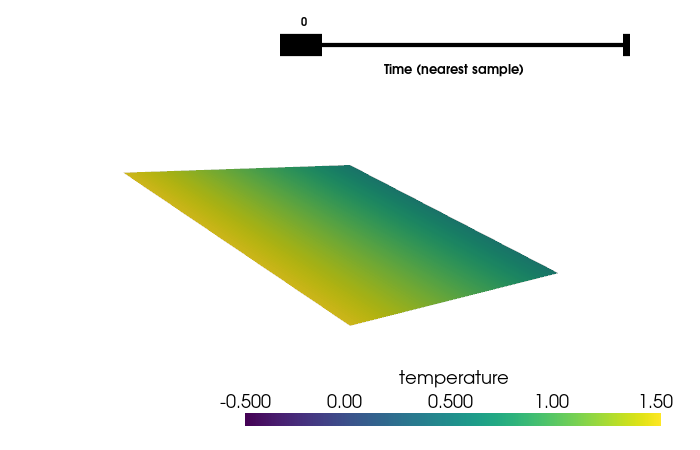

In [5]:
final_image = pl.screenshot(return_img=True)
assert np.mean(np.abs(final_image.astype(float) - initial_image.astype(float))) > 1.0
assert np.count_nonzero(np.any(final_image[:, :, :3] < 200, axis=2)) > 1000
pl.show(jupyter_backend='static')

## Optional live slider
Change `RUN_INTERACTIVE` to `True` and run this cell to open a desktop window. A desktop display is required. Closing the window returns control to the notebook.

In [6]:
RUN_INTERACTIVE = False
if RUN_INTERACTIVE:
    saved_off_screen = pv.OFF_SCREEN
    try:
        pv.OFF_SCREEN = False
        live_pl = pv.Plotter()
        live_controller = TimeController(live_pl, [0.0, 0.2, 1.0], frames.__getitem__,
                                         scalars='temperature', clim=(-0.5, 1.5))
        live_pl.camera_position = 'iso'
        live_pl.show(jupyter=False)
    finally:
        pv.OFF_SCREEN = saved_off_screen